# Dinâmica distribucional: cadeia de Markov, 2002–2023

Classifica os estados em cinco faixas de renda relativa ao PIB per capita do Brasil, estima a matriz de transição anual e calcula as distribuições projetada e de longo prazo (seção 4.4.2 do TCC).

Os dados vêm do Ipeadata e devem estar na pasta `../dados_usados` (ver o README do repositório).

In [13]:
# ----------------------------------------------------------------------------
# 1. BIBLIOTECAS E PARÂMETROS
# ----------------------------------------------------------------------------
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# As séries do Brasil e do deflator vêm do Ipeadata em formato .xls (Excel antigo).
# O pandas só lê esse formato com o pacote xlrd. Se ele não estiver instalado,
# a linha abaixo o instala automaticamente (é preciso estar conectado à internet).
import importlib.util, subprocess, sys
if importlib.util.find_spec("xlrd") is None:
    print("Pacote xlrd não encontrado; instalando...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "xlrd>=2.0.1"])
    importlib.invalidate_caches()

# O notebook fica na pasta QUAH; os dados, em TCC\dados_usados
PASTA_DADOS = os.path.join("..", "dados_usados")
ARQ_ESTADOS  = os.path.join(PASTA_DADOS, "PIBPCE_pib_estadual_per_capita_precos_2010_[17-08-2026].csv")
ARQ_BRASIL   = os.path.join(PASTA_DADOS, "GAC_PIBCAPN_pib_per_capita_brasil_nominal_[04-11-2026].xls")
ARQ_DEFLATOR = os.path.join(PASTA_DADOS, "SCN10_DIPIBG10_deflator_implicito_pib_[04-11-2026].xls")

ANO_INICIAL = 2002
ANO_FINAL   = 2023
ANO_BASE    = 2010                        # preços de 2010, como a série estadual
HORIZONTE   = ANO_FINAL - ANO_INICIAL     # 21 passos anuais

N_FAIXAS     = 5
CORTES_FIXOS = [0.5, 0.75, 1.0, 1.5]

for pasta in ["resultados/figuras", "resultados/tabelas", "dados/tratados"]:
    os.makedirs(pasta, exist_ok=True)

pd.set_option("display.float_format", lambda v: f"{v:.3f}")
pd.set_option("display.width", 160)

Pacote xlrd não encontrado; instalando...


In [14]:
# ----------------------------------------------------------------------------
# 2. LEITURA: PIB PER CAPITA DOS ESTADOS (preços de 2010)
# ----------------------------------------------------------------------------
df = pd.read_csv(ARQ_ESTADOS, skiprows=1, encoding="utf-8-sig")
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
anos = [c for c in df.columns if c.isdigit()]
largo = df.set_index("Sigla")[anos].astype(float)
largo.columns = largo.columns.astype(int)

assert largo.shape == (27, 22), f"Esperado 27 UF x 22 anos, obtido {largo.shape}"
assert largo.isna().sum().sum() == 0, "Há valores ausentes"
print(f"Estados: {largo.shape[0]} UF, {largo.columns.min()}-{largo.columns.max()} (R$ mil de 2010)")

Estados: 27 UF, 2002-2023 (R$ mil de 2010)


In [15]:
# ----------------------------------------------------------------------------
# 3. PIB PER CAPITA DO BRASIL A PREÇOS DE 2010
# ----------------------------------------------------------------------------
def ler_serie_ipeadata(caminho):
    """Lê uma série anual exportada do Ipeadata (.xls): coluna Data + coluna de valores."""
    x = pd.read_excel(caminho, header=0)
    x.columns = ["ano", "valor"]
    x = x[x["ano"].astype(str).str.fullmatch(r"\d{4}")]
    return pd.Series(x["valor"].astype(float).values, index=x["ano"].astype(int).values)

brasil_nominal = ler_serie_ipeadata(ARQ_BRASIL)       # R$ mil correntes
deflator_var   = ler_serie_ipeadata(ARQ_DEFLATOR)     # variação anual, % a.a.

# Índice do deflator com 2010 = 1:
#   depois de 2010: I(t) = I(t-1) x (1 + var(t)/100)
#   antes de 2010:  I(t-1) = I(t) / (1 + var(t)/100)
indice = {ANO_BASE: 1.0}
for t in range(ANO_BASE + 1, ANO_FINAL + 1):
    indice[t] = indice[t - 1] * (1 + deflator_var[t] / 100)
for t in range(ANO_BASE, ANO_INICIAL, -1):
    indice[t - 1] = indice[t] / (1 + deflator_var[t] / 100)
indice = pd.Series(indice).sort_index().loc[ANO_INICIAL:ANO_FINAL]

brasil_real = (brasil_nominal.loc[ANO_INICIAL:ANO_FINAL] / indice)   # R$ mil de 2010
media_simples = largo.mean(axis=0)

tab_ref = pd.DataFrame({
    "Brasil nominal (R$ mil)": brasil_nominal.loc[ANO_INICIAL:ANO_FINAL],
    "Var. deflator (%)": deflator_var.loc[ANO_INICIAL:ANO_FINAL],
    "Índice (2010 = 1)": indice,
    "Brasil a preços de 2010": brasil_real,
    "Média simples das UF": media_simples,
    "Brasil / média simples": brasil_real / media_simples,
})
print(tab_ref.to_string())

      Brasil nominal (R$ mil)  Var. deflator (%)  Índice (2010 = 1)  Brasil a preços de 2010  Média simples das UF  Brasil / média simples
2002                    8.521              9.798              0.526                   16.188                13.536                   1.196
2003                    9.722             14.091              0.601                   16.189                13.569                   1.193
2004                   10.967              7.752              0.647                   16.947                13.998                   1.211
2005                   12.041              7.431              0.695                   17.320                14.089                   1.229
2006                   13.235              6.774              0.742                   17.830                14.462                   1.233
2007                   14.785              6.439              0.790                   18.713                15.044                   1.244
2008                   16.7

In [16]:
# ----------------------------------------------------------------------------
# 4. FUNÇÕES DO MÉTODO
# ----------------------------------------------------------------------------
def renda_relativa(niveis, referencia):
    """Passo 0. Divide a renda de cada estado pela referência do mesmo ano."""
    return niveis.div(referencia, axis=1)


def classificar(relativa, cortes):
    """Passo 1. Faixa de cada observação (1 = mais pobre)."""
    return relativa.apply(lambda coluna: pd.Series(np.digitize(coluna, cortes) + 1,
                                                    index=coluna.index))


def rotulos_faixas(cortes):
    c = [f"{x:.2f}".replace(".", ",") for x in cortes]
    rot = [f"F1 (< {c[0]})"]
    rot += [f"F{k + 1} ({c[k - 1]}–{c[k]})" for k in range(1, len(c))]
    rot += [f"F{len(c) + 1} (≥ {c[-1]})"]
    return rot


def contar_transicoes(faixas, horizonte=1):
    """Passo 2. Conta as transições da faixa j para a faixa l em todos os pares de anos."""
    N = np.zeros((N_FAIXAS, N_FAIXAS), dtype=int)
    anos_ = list(faixas.columns)
    for t0, t1 in zip(anos_[:-horizonte], anos_[horizonte:]):
        for j, l in zip(faixas[t0], faixas[t1]):
            N[j - 1, l - 1] += 1
    return N


def matriz_transicao(N):
    """Passo 3. p_jl = n_jl / n_j (máxima verossimilhança)."""
    n_j = N.sum(axis=1)
    assert (n_j > 0).all(), "Há faixa sem nenhuma transição partindo dela"
    return N / n_j[:, None], n_j


def ergodica(P):
    """Passo 4. f* = f* P: autovetor à esquerda associado ao autovalor 1."""
    autovalores, autovetores = np.linalg.eig(P.T)
    n_unitarios = int(np.sum(np.isclose(autovalores, 1, atol=1e-8)))
    i = np.argmin(np.abs(autovalores - 1))
    f = np.real(autovetores[:, i]); f = f / f.sum()
    assert np.allclose(np.linalg.matrix_power(P, 100000), f[None, :], atol=1e-6), \
        "Iteração não converge para a ergódica"
    lambda2 = np.sort(np.abs(autovalores))[::-1][1]
    return f, n_unitarios, lambda2


def distribuicao(faixas_ano):
    contagem = np.bincount(faixas_ano, minlength=N_FAIXAS + 1)[1:]
    return contagem / contagem.sum()


def analisar(niveis, referencia, rotulo):
    rel = renda_relativa(niveis, referencia)
    faixas = classificar(rel, CORTES_FIXOS)
    N = contar_transicoes(faixas)
    P, n_j = matriz_transicao(N)
    f_erg, n_unit, lambda2 = ergodica(P)
    f_ini, f_fim = distribuicao(faixas[ANO_INICIAL]), distribuicao(faixas[ANO_FINAL])
    return {
        "rotulo": rotulo, "rel": rel, "faixas": faixas, "rot": rotulos_faixas(CORTES_FIXOS),
        "N": N, "P": P, "n_j": n_j, "erg": f_erg, "n_unitarios": n_unit,
        "lambda2": lambda2, "meia_vida_erg": np.log(0.5) / np.log(lambda2),
        "f_ini": f_ini, "f_fim": f_fim,
        "f_proj": f_ini @ np.linalg.matrix_power(P, HORIZONTE),
        "n_estados": niveis.shape[0], "n_transicoes": int(N.sum()),
        "mudancas": int(N.sum() - np.trace(N)), "ocupacao": n_j / n_j.sum(),
    }


# PRINCIPAL: 27 UF, referência = PIB per capita do Brasil a preços de 2010
princ = analisar(largo, brasil_real, "Principal: referência Brasil (27 UF)")
# ROBUSTEZ: sem o DF na cadeia (referência continua sendo o Brasil)
sem_df = analisar(largo.drop(index="DF"), brasil_real, "Robustez: sem o DF (referência Brasil)")
# COMPARAÇÃO: versão anterior, com a média simples das 27 UF
simples = analisar(largo, media_simples, "Comparação: média simples (versão anterior)")

ESPECIFICACOES = (princ, sem_df, simples)
for r in ESPECIFICACOES:
    print(f"{r['rotulo']}: {r['n_estados']} estados, {r['n_transicoes']} transições, "
          f"{r['mudancas']} mudanças de faixa ({r['mudancas'] / r['n_transicoes']:.1%}); "
          f"autovalores iguais a 1: {r['n_unitarios']}; 2º autovalor: {r['lambda2']:.3f} "
          f"(meia-vida até a ergódica: {r['meia_vida_erg']:.0f} anos)")

Principal: referência Brasil (27 UF): 27 estados, 567 transições, 43 mudanças de faixa (7.6%); autovalores iguais a 1: 1; 2º autovalor: 0.976 (meia-vida até a ergódica: 28 anos)
Robustez: sem o DF (referência Brasil): 26 estados, 546 transições, 43 mudanças de faixa (7.9%); autovalores iguais a 1: 1; 2º autovalor: 0.975 (meia-vida até a ergódica: 27 anos)
Comparação: média simples (versão anterior): 27 estados, 567 transições, 38 mudanças de faixa (6.7%); autovalores iguais a 1: 1; 2º autovalor: 0.977 (meia-vida até a ergódica: 30 anos)


In [17]:
# ----------------------------------------------------------------------------
# 5. CORTES DAS FAIXAS EM REAIS
# ----------------------------------------------------------------------------
tab_cortes = pd.DataFrame([{
    "Limite entre": f"F{k} e F{k + 1}", "Renda relativa": c,
    f"Equivale em {ANO_INICIAL} (R$ mil de 2010)": c * brasil_real[ANO_INICIAL],
    f"Equivale em {ANO_FINAL} (R$ mil de 2010)": c * brasil_real[ANO_FINAL],
} for k, c in enumerate(CORTES_FIXOS, start=1)])
print(tab_cortes.to_string(index=False))

Limite entre  Renda relativa  Equivale em 2002 (R$ mil de 2010)  Equivale em 2023 (R$ mil de 2010)
     F1 e F2           0.500                              8.094                             10.967
     F2 e F3           0.750                             12.141                             16.450
     F3 e F4           1.000                             16.188                             21.933
     F4 e F5           1.500                             24.282                             32.900


In [18]:
# ----------------------------------------------------------------------------
# 6. MATRIZ DE TRANSIÇÃO ANUAL — PRINCIPAL (formato da Tabela 1 de Quah, 1993a)
# ----------------------------------------------------------------------------
def tabela_matriz(r):
    tab = pd.DataFrame(r["P"], index=r["rot"], columns=r["rot"])
    tab.insert(0, "Nº de transições", r["n_j"])
    erg = pd.DataFrame([[np.nan] + list(r["erg"])], index=["Ergódica"], columns=tab.columns)
    tab = pd.concat([tab, erg])
    tab["Nº de transições"] = tab["Nº de transições"].astype("Int64")
    return tab

tab_P = tabela_matriz(princ)
print(tab_P.to_string())
print("\nContagem das transições:\n")
print(pd.DataFrame(princ["N"], index=princ["rot"], columns=princ["rot"]).to_string())

                Nº de transições  F1 (< 0,50)  F2 (0,50–0,75)  F3 (0,75–1,00)  F4 (1,00–1,50)  F5 (≥ 1,50)
F1 (< 0,50)                  120        0.942           0.058           0.000           0.000        0.000
F2 (0,50–0,75)               196        0.026           0.944           0.031           0.000        0.000
F3 (0,75–1,00)                86        0.000           0.058           0.837           0.105        0.000
F4 (1,00–1,50)               135        0.000           0.000           0.044           0.941        0.015
F5 (≥ 1,50)                   30        0.000           0.000           0.000           0.100        0.900
Ergódica                    <NA>        0.129           0.295           0.155           0.366        0.054

Contagem das transições:

                F1 (< 0,50)  F2 (0,50–0,75)  F3 (0,75–1,00)  F4 (1,00–1,50)  F5 (≥ 1,50)
F1 (< 0,50)             113               7               0               0            0
F2 (0,50–0,75)            5             185   

In [19]:
# ----------------------------------------------------------------------------
# 7. DISTRIBUIÇÕES — PRINCIPAL: 2002, 2023, 2023 projetada (P^21) e ergódica
# ----------------------------------------------------------------------------
def tabela_distribuicoes(r):
    tab = pd.DataFrame({
        f"{ANO_INICIAL} observada": r["f_ini"], f"{ANO_FINAL} observada": r["f_fim"],
        f"{ANO_FINAL} projetada (P^{HORIZONTE})": r["f_proj"],
        "Ocupação média": r["ocupacao"], "Ergódica": r["erg"],
    }, index=r["rot"])
    tab_n = tab * r["n_estados"]
    tab_n.columns = [c + " (nº de estados)" for c in tab.columns]
    return tab, tab_n

tab_dist, tab_dist_n = tabela_distribuicoes(princ)
print(tab_dist.to_string()); print()
print(tab_dist_n.to_string(float_format=lambda v: f"{v:.1f}"))

                2002 observada  2023 observada  2023 projetada (P^21)  Ocupação média  Ergódica
F1 (< 0,50)              0.222           0.148                  0.169           0.212     0.129
F2 (0,50–0,75)           0.296           0.333                  0.338           0.346     0.295
F3 (0,75–1,00)           0.259           0.185                  0.145           0.152     0.155
F4 (1,00–1,50)           0.148           0.296                  0.303           0.238     0.366
F5 (≥ 1,50)              0.074           0.037                  0.045           0.053     0.054

                2002 observada (nº de estados)  2023 observada (nº de estados)  2023 projetada (P^21) (nº de estados)  Ocupação média (nº de estados)  Ergódica (nº de estados)
F1 (< 0,50)                                6.0                             4.0                                    4.6                             5.7                       3.5
F2 (0,50–0,75)                             8.0                         

In [20]:
# ----------------------------------------------------------------------------
# 8. LONGO HORIZONTE — PRINCIPAL: observada (2002 -> 2023) x P^21
# ----------------------------------------------------------------------------
fx = princ["faixas"]
cruz = pd.crosstab(fx[ANO_INICIAL], fx[ANO_FINAL]).reindex(
    index=range(1, N_FAIXAS + 1), columns=range(1, N_FAIXAS + 1), fill_value=0)
cruz.index, cruz.columns = princ["rot"], princ["rot"]
cruz_prop = cruz.div(cruz.sum(axis=1).replace(0, np.nan), axis=0)
P21 = pd.DataFrame(np.linalg.matrix_power(princ["P"], HORIZONTE),
                   index=princ["rot"], columns=princ["rot"])
diag = pd.DataFrame({
    f"Permanência observada {ANO_INICIAL}-{ANO_FINAL}": np.diag(cruz_prop.to_numpy()),
    f"Permanência prevista por P^{HORIZONTE}": np.diag(P21.to_numpy()),
}, index=princ["rot"])
print(cruz.to_string()); print(); print(diag.to_string())

                F1 (< 0,50)  F2 (0,50–0,75)  F3 (0,75–1,00)  F4 (1,00–1,50)  F5 (≥ 1,50)
F1 (< 0,50)               4               2               0               0            0
F2 (0,50–0,75)            0               6               2               0            0
F3 (0,75–1,00)            0               1               3               3            0
F4 (1,00–1,50)            0               0               0               4            0
F5 (≥ 1,50)               0               0               0               1            1

                Permanência observada 2002-2023  Permanência prevista por P^21
F1 (< 0,50)                               0.667                          0.394
F2 (0,50–0,75)                            0.750                          0.495
F3 (0,75–1,00)                            0.429                          0.182
F4 (1,00–1,50)                            1.000                          0.578
F5 (≥ 1,50)                               0.500                       

In [21]:
# ----------------------------------------------------------------------------
# 9. ESTADOS POR FAIXA EM 2002 E 2023 — PRINCIPAL
# ----------------------------------------------------------------------------
estados = pd.DataFrame({
    "Estado": largo.index.map(df.set_index("Sigla")["Estado"]),
    f"Renda rel. {ANO_INICIAL}": princ["rel"][ANO_INICIAL], f"Faixa {ANO_INICIAL}": fx[ANO_INICIAL],
    f"Renda rel. {ANO_FINAL}": princ["rel"][ANO_FINAL], f"Faixa {ANO_FINAL}": fx[ANO_FINAL],
}, index=largo.index)
estados["Movimento"] = np.select(
    [estados[f"Faixa {ANO_FINAL}"] > estados[f"Faixa {ANO_INICIAL}"],
     estados[f"Faixa {ANO_FINAL}"] < estados[f"Faixa {ANO_INICIAL}"]],
    ["subiu", "desceu"], default="manteve")
estados["Mudanças anuais"] = (fx.diff(axis=1).iloc[:, 1:] != 0).sum(axis=1)
estados = estados.sort_values([f"Faixa {ANO_INICIAL}", f"Renda rel. {ANO_INICIAL}"])
print(estados.to_string())

resumo_faixas = pd.DataFrame({
    f"Estados em {ANO_INICIAL}": [", ".join(sorted(fx.index[fx[ANO_INICIAL] == k])) for k in range(1, N_FAIXAS + 1)],
    f"Estados em {ANO_FINAL}": [", ".join(sorted(fx.index[fx[ANO_FINAL] == k])) for k in range(1, N_FAIXAS + 1)],
}, index=princ["rot"])
print(); print(resumo_faixas.to_string())

                    Estado  Renda rel. 2002  Faixa 2002  Renda rel. 2023  Faixa 2023 Movimento  Mudanças anuais
Sigla                                                                                                          
PI                   Piauí            0.288           1            0.460           1   manteve                0
MA                Maranhão            0.322           1            0.410           1   manteve                0
PB                 Paraíba            0.428           1            0.453           1   manteve                0
CE                   Ceará            0.440           1            0.490           1   manteve                2
AL                 Alagoas            0.469           1            0.535           2     subiu                3
PA                    Pará            0.482           1            0.581           2     subiu                1
TO               Tocantins            0.518           2            0.788           3     subiu          

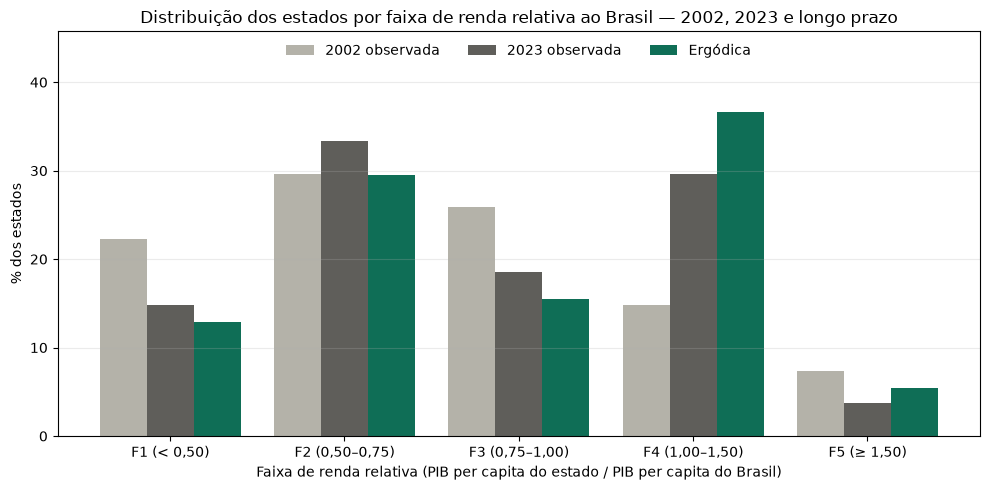

In [22]:
# ----------------------------------------------------------------------------
# 10. GRÁFICO — PRINCIPAL: distribuições de 2002, 2023 e ergódica
# ----------------------------------------------------------------------------
x = np.arange(N_FAIXAS); largura = 0.27
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - largura, princ["f_ini"] * 100, largura, label=f"{ANO_INICIAL} observada", color="#B4B2A9")
ax.bar(x,           princ["f_fim"] * 100, largura, label=f"{ANO_FINAL} observada",   color="#5F5E5A")
ax.bar(x + largura, princ["erg"] * 100,   largura, label="Ergódica",                 color="#0F6E56")
ax.set_xticks(x); ax.set_xticklabels(princ["rot"])
ax.set_ylabel("% dos estados")
ax.set_xlabel("Faixa de renda relativa (PIB per capita do estado / PIB per capita do Brasil)")
ax.set_title(f"Distribuição dos estados por faixa de renda relativa ao Brasil — {ANO_INICIAL}, {ANO_FINAL} e longo prazo")
ax.set_ylim(0, max(princ["f_ini"].max(), princ["f_fim"].max(), princ["erg"].max()) * 100 * 1.25)
ax.legend(frameon=False, ncol=3, loc="upper center")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig("resultados/figuras/markov_brasil_distribuicoes.png", dpi=200)
plt.show()

In [23]:
# ----------------------------------------------------------------------------
# 11. ROBUSTEZ E COMPARAÇÃO COM A VERSÃO ANTERIOR (média simples)
# ----------------------------------------------------------------------------
comparacao = []
for r in ESPECIFICACOES:
    linha = {"Especificação": r["rotulo"],
             "Mudanças de faixa (%)": 100 * r["mudancas"] / r["n_transicoes"],
             "2º autovalor": r["lambda2"],
             "Meia-vida até a ergódica (anos)": r["meia_vida_erg"]}
    for k in range(N_FAIXAS):
        linha[f"F{k + 1} {ANO_INICIAL}"] = r["f_ini"][k]
        linha[f"F{k + 1} {ANO_FINAL}"] = r["f_fim"][k]
        linha[f"F{k + 1} ergódica"] = r["erg"][k]
    comparacao.append(linha)
comparacao = pd.DataFrame(comparacao)
print(comparacao.T.to_string(header=False))

for r in (sem_df, simples):
    print(f"\n{'=' * 90}\n{r['rotulo']}\n")
    print(tabela_matriz(r).to_string()); print()
    print(tabela_distribuicoes(r)[0].to_string())

Especificação                    Principal: referência Brasil (27 UF)  Robustez: sem o DF (referência Brasil)  Comparação: média simples (versão anterior)
Mudanças de faixa (%)                                           7.584                                   7.875                                        6.702
2º autovalor                                                    0.976                                   0.975                                        0.977
Meia-vida até a ergódica (anos)                                28.482                                  26.956                                       29.798
F1 2002                                                         0.222                                   0.231                                        0.074
F1 2023                                                         0.148                                   0.154                                        0.037
F1 ergódica                                                     0.129 

In [24]:
# ----------------------------------------------------------------------------
# 12. SALVAR PRODUTOS
# ----------------------------------------------------------------------------
tab_ref.to_csv("resultados/tabelas/markov_brasil_referencia.csv")
tab_cortes.to_csv("resultados/tabelas/markov_brasil_cortes.csv", index=False)
tab_P.to_csv("resultados/tabelas/markov_brasil_matriz_anual.csv")
tab_dist.to_csv("resultados/tabelas/markov_brasil_distribuicoes.csv")
tab_dist_n.to_csv("resultados/tabelas/markov_brasil_distribuicoes_n_estados.csv")
cruz.to_csv("resultados/tabelas/markov_brasil_transicoes_2002_2023.csv")
P21.to_csv("resultados/tabelas/markov_brasil_P21.csv")
diag.to_csv("resultados/tabelas/markov_brasil_diagonais_longo_horizonte.csv")
estados.to_csv("resultados/tabelas/markov_brasil_estados_por_faixa.csv")
resumo_faixas.to_csv("resultados/tabelas/markov_brasil_resumo_faixas.csv")
comparacao.to_csv("resultados/tabelas/markov_brasil_comparacao_especificacoes.csv", index=False)
tabela_matriz(sem_df).to_csv("resultados/tabelas/markov_brasil_matriz_anual_sem_df.csv")
print("Tabelas e figura salvas em resultados/.")

Tabelas e figura salvas em resultados/.
